<a href="https://colab.research.google.com/github/saraxfl/Notebook/blob/main/Collab7_Bloque2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 7. ViT y CNN en imágenes EuroSAT

Comparación de los dos clasificadores con los mismos datos de prueba. El experimento usa 500, 2,500 y 21,600 imágenes de entrenamiento, tres semillas y 2,000 actualizaciones por combinación.


Dispositivo: cpu
El experimento completo en CPU puede tardar horas. Para comprobar el flujo activa PRUEBA_RAPIDA.


100%|██████████| 94.3M/94.3M [00:00<00:00, 103MB/s]


Banco de entrenamiento: 21,600 · prueba: 5,400


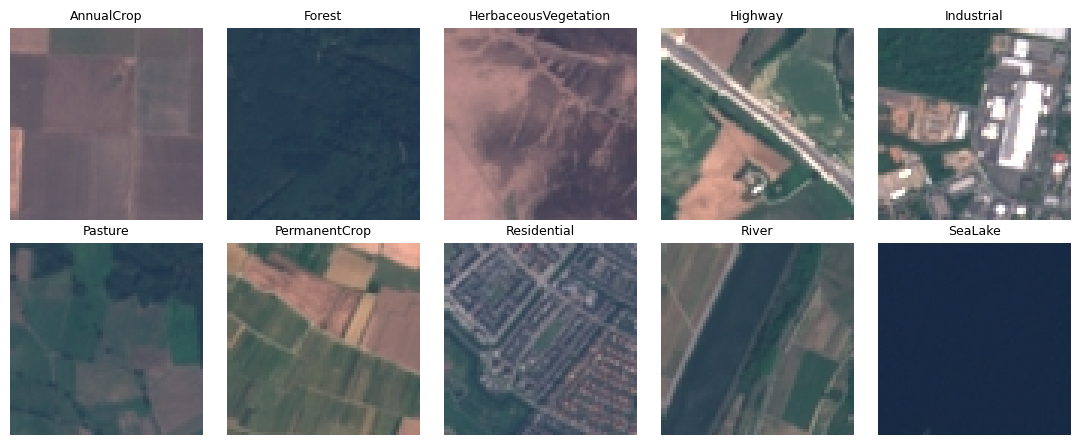

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torchvision.datasets import EuroSAT
from sklearn.model_selection import train_test_split

PRUEBA_RAPIDA = False
dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {dispositivo}")
if dispositivo.type == "cpu" and not PRUEBA_RAPIDA:
    print("El experimento completo en CPU puede tardar horas. Para comprobar el flujo activa PRUEBA_RAPIDA.")

datos = EuroSAT("datos_eurosat", download=True)
clases = datos.classes
etiquetas = np.asarray(datos.targets)
indices_ent, indices_test = train_test_split(
    np.arange(len(datos)), test_size=.2, stratify=etiquetas, random_state=0
)
imagenes = torch.stack([
    torch.from_numpy(np.array(datos[i][0], dtype=np.uint8)).permute(2, 0, 1)
    for i in range(len(datos))
])
objetivos = torch.from_numpy(etiquetas).long()
print(f"Banco de entrenamiento: {len(indices_ent):,} · prueba: {len(indices_test):,}")

fig, ejes = plt.subplots(2, 5, figsize=(11, 4.5))
for numero, eje in enumerate(ejes.flat):
    muestra = np.flatnonzero(etiquetas == numero)[0]
    eje.imshow(imagenes[muestra].permute(1, 2, 0))
    eje.set_title(clases[numero], fontsize=9)
    eje.axis("off")
fig.tight_layout()
plt.show()

In [2]:
def calcular_normalizacion(indices):
    suma = torch.zeros(3, dtype=torch.float64)
    cuadrados = torch.zeros_like(suma)
    total = 0
    for lote in np.array_split(indices, 32):
        pixeles = imagenes[lote].to(torch.float64) / 255
        suma += pixeles.sum(dim=(0, 2, 3))
        cuadrados += pixeles.square().sum(dim=(0, 2, 3))
        total += len(lote) * pixeles.shape[-1] * pixeles.shape[-2]
    media = suma / total
    varianza = (cuadrados - total * media.square()) / (total - 1)
    return media.float().view(1, 3, 1, 1), varianza.sqrt().float().view(1, 3, 1, 1)


media, desviacion = calcular_normalizacion(indices_ent)
media, desviacion = media.to(dispositivo), desviacion.to(dispositivo)

def convertir(lote):
    return (lote.to(dispositivo, dtype=torch.float32) / 255 - media) / desviacion


def subconjunto_por_clase(cupo, semilla):
    if cupo is None:
        return np.sort(indices_ent)
    azar = np.random.default_rng(semilla)
    grupos = [azar.permutation(indices_ent[etiquetas[indices_ent] == clase])[:cupo]
              for clase in range(len(clases))]
    return np.sort(np.concatenate(grupos))


# Un parche de 8 × 8 RGB equivale a 192 entradas antes de proyectarlo.
muestra = convertir(imagenes[indices_test[:1]])
parches = F.unfold(muestra, kernel_size=8, stride=8)
reconstruida = F.fold(parches, output_size=(64, 64), kernel_size=8, stride=8)
assert torch.equal(muestra, reconstruida)
print("Parches por imagen y valores por parche:", parches.transpose(1, 2).shape[1:])

proyeccion = nn.Conv2d(3, 128, kernel_size=8, stride=8).to(dispositivo)
with torch.inference_mode():
    con_lineal = F.linear(parches.transpose(1, 2), proyeccion.weight.flatten(1), proyeccion.bias)
    con_conv = proyeccion(muestra).flatten(2).transpose(1, 2)
    print(f"Diferencia máxima entre las dos proyecciones: {(con_lineal-con_conv).abs().max().item():.2g}")

Parches por imagen y valores por parche: torch.Size([64, 192])
Diferencia máxima entre las dos proyecciones: 1.1e-06


In [3]:
class ClasificadorViT(nn.Module):
    def __init__(self, posiciones=True):
        super().__init__()
        self.parches = nn.Conv2d(3, 128, kernel_size=8, stride=8)
        self.token = nn.Parameter(torch.randn(1, 1, 128) * .02)
        self.posiciones = nn.Parameter(torch.randn(1, 65, 128) * .02) if posiciones else None
        # Creo cada bloque por separado para que tenga inicialización independiente.
        self.encoder = nn.Sequential(*[
            nn.TransformerEncoderLayer(128, 4, dim_feedforward=256, dropout=0.,
                                       activation="gelu", batch_first=True, norm_first=True)
            for _ in range(3)
        ])
        self.clasificar = nn.Sequential(nn.LayerNorm(128), nn.Linear(128, len(clases)))

    def forward(self, lote):
        fichas = self.parches(lote).flatten(2).transpose(1, 2)
        secuencia = torch.cat([self.token.expand(len(lote), -1, -1), fichas], dim=1)
        if self.posiciones is not None:
            secuencia = secuencia + self.posiciones
        return self.clasificar(self.encoder(secuencia)[:, 0])


class ClasificadorCNN(nn.Module):
    def __init__(self):
        super().__init__()
        capas = []
        canales = (3, 32, 64, 128, 256)
        for entrada, salida in zip(canales, canales[1:]):
            capas.extend([
                nn.Conv2d(entrada, salida, kernel_size=3, padding=1),
                nn.BatchNorm2d(salida), nn.ReLU(), nn.MaxPool2d(2),
            ])
        self.red = nn.Sequential(*capas, nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                 nn.Linear(256, len(clases)))

    def forward(self, lote):
        return self.red(lote)


with torch.inference_mode():
    permutacion = torch.randperm(64, generator=torch.Generator().manual_seed(1)).to(dispositivo)
    reordenada = F.fold(parches[:, :, permutacion], (64, 64), kernel_size=8, stride=8)
    for posiciones in (False, True):
        torch.manual_seed(0)
        vit = ClasificadorViT(posiciones).to(dispositivo).eval()
        diferencia = (vit(muestra) - vit(reordenada)).abs().max().item()
        print(f"Posiciones {posiciones} · cambio máximo al reordenar parches: {diferencia:.3g}")

Posiciones False · cambio máximo al reordenar parches: 4.32e-07
Posiciones True · cambio máximo al reordenar parches: 0.00692


In [ ]:
def aumentar(lote):
    for eje in (3, 2):
        mascara = torch.rand((len(lote), 1, 1, 1), device=dispositivo) < .5
        lote = torch.where(mascara, lote.flip(eje), lote)
    return lote


def ajustar_modelo(constructor, indices, semilla, pasos):
    torch.manual_seed(semilla)
    modelo = constructor().to(dispositivo)
    optim = torch.optim.AdamW(modelo.parameters(), lr=.001, weight_decay=.05)
    agenda = torch.optim.lr_scheduler.OneCycleLR(optim, max_lr=.001, total_steps=pasos, pct_start=.1)
    azar = torch.Generator().manual_seed(semilla)
    grupo = torch.as_tensor(indices)
    modelo.train()
    for _ in range(pasos):
        posiciones = torch.randint(len(grupo), (128,), generator=azar)
        ids = grupo[posiciones]
        lote = aumentar(convertir(imagenes[ids]))
        optim.zero_grad(set_to_none=True)
        perdida = F.cross_entropy(modelo(lote), objetivos[ids].to(dispositivo))
        perdida.backward()
        optim.step()
        agenda.step()
    return modelo


@torch.inference_mode()
def exactitud(modelo, indices):
    modelo.eval()
    aciertos = 0
    for inicio in range(0, len(indices), 256):
        ids = indices[inicio:inicio + 256]
        prediccion = modelo(convertir(imagenes[ids])).argmax(dim=1).cpu()
        aciertos += (prediccion == objetivos[ids]).sum().item()
    return aciertos / len(indices)


# En modo rápido ejecuto ambos modelos en un subconjunto, solo para validar el flujo.
cupos = (5,) if PRUEBA_RAPIDA else (50, 250, None)
semillas = (0,) if PRUEBA_RAPIDA else (0, 1, 2)
pasos = 12 if PRUEBA_RAPIDA else 2000
evaluar_en = indices_test[:256] if PRUEBA_RAPIDA else indices_test
registros = []
for cupo in cupos:
    for semilla in semillas:
        ids_ent = subconjunto_por_clase(cupo, semilla)
        for nombre, constructor in (("ViT", ClasificadorViT), ("CNN", ClasificadorCNN)):
            modelo = ajustar_modelo(constructor, ids_ent, semilla, pasos)
            acc = exactitud(modelo, evaluar_en)
            registros.append((nombre, len(ids_ent), semilla, acc))
            print(f"{nombre} · {len(ids_ent):,} imágenes · semilla {semilla} · exactitud {acc:.2%}", flush=True)
            del modelo

In [ ]:
resultados = pd.DataFrame(registros, columns=["Modelo", "Imágenes", "Semilla", "Exactitud"])
display(resultados.round(4))
resumen = resultados.groupby(["Modelo", "Imágenes"])["Exactitud"].agg(["mean", "std"])
display(resumen.rename(columns={"mean": "Media", "std": "Desv. estándar"}).round(4))

fig, eje = plt.subplots(figsize=(8, 4))
for nombre in resumen.index.get_level_values("Modelo").unique():
    estad = resumen.loc[nombre]
    eje.errorbar(estad.index, 100 * estad["mean"], yerr=100 * estad["std"].fillna(0),
                 marker="o", capsize=4, label=nombre)
eje.set(xscale="log", xlabel="Imágenes de entrenamiento", ylabel="Exactitud en prueba (%)",
        title="Exactitud según tamaño de entrenamiento")
eje.legend()
fig.tight_layout()
plt.show()